# 04 — Model Training

Trains and compares 4 classification models, tunes the best one, and
saves the final preprocessing+model pipeline. This notebook calls
`src/train.py` directly so there is exactly one source of truth for the
training logic (no drift between notebook and production code) — the
notebook then loads and displays the results.

In [1]:
import sys, os, json
sys.path.insert(0, os.path.abspath('../src'))
os.chdir('..')  # run from project root, same as `python src/train.py`
import train
train.main()
os.chdir('notebooks')


[LogisticRegression] {'accuracy': 0.7367, 'precision': 0.5026, 'recall': 0.7888, 'f1_score': 0.6139, 'roc_auc': 0.8424, 'cv_roc_auc_mean': np.float64(0.8457), 'cv_roc_auc_std': np.float64(0.0113)}
[DecisionTree] {'accuracy': 0.7253, 'precision': 0.489, 'recall': 0.7701, 'f1_score': 0.5981, 'roc_auc': 0.7944, 'cv_roc_auc_mean': np.float64(0.7853), 'cv_roc_auc_std': np.float64(0.0039)}
[RandomForest] {'accuracy': 0.7757, 'precision': 0.6, 'recall': 0.4652, 'f1_score': 0.5241, 'roc_auc': 0.8182, 'cv_roc_auc_mean': np.float64(0.8237), 'cv_roc_auc_std': np.float64(0.0106)}
[GradientBoosting] {'accuracy': 0.802, 'precision': 0.6644, 'recall': 0.5134, 'f1_score': 0.5792, 'roc_auc': 0.8433, 'cv_roc_auc_mean': np.float64(0.8479), 'cv_roc_auc_std': np.float64(0.0121)}

Selected as business-best model: LogisticRegression
Reason: highest weighted score of ROC-AUC (ranking quality) and Recall (catching actual churners), since missing a churner is costlier than a false alarm.

Best params for Logist

## Load the saved report for inspection

In [2]:
with open('../reports/model_report.json') as f:
    report = json.load(f)

import pandas as pd
comparison_df = pd.DataFrame(report['model_comparison']).T
comparison_df
print(comparison_df.to_string())


                    accuracy  precision  recall  f1_score  roc_auc  cv_roc_auc_mean  cv_roc_auc_std
LogisticRegression    0.7367     0.5026  0.7888    0.6139   0.8424           0.8457          0.0113
DecisionTree          0.7253     0.4890  0.7701    0.5981   0.7944           0.7853          0.0039
RandomForest          0.7757     0.6000  0.4652    0.5241   0.8182           0.8237          0.0106
GradientBoosting      0.8020     0.6644  0.5134    0.5792   0.8433           0.8479          0.0121


## Business-informed model selection

For churn prediction, a **False Negative** (predicted "won't churn" but
the customer actually leaves) means the retention team never reaches out
— a guaranteed lost customer. A **False Positive** (predicted "will
churn" but the customer stays) only costs an unnecessary outreach or
discount to an already-happy customer — a much cheaper mistake.

So the model is selected on a weighted score of **ROC-AUC** (ranking
quality across all thresholds) and **Recall** (share of actual churners
caught), not raw accuracy.

In [3]:
print("Selected model:", report['selected_model'])
print()
print(report['selection_rationale'])


Selected model: LogisticRegression

Weighted score = 0.6*ROC-AUC + 0.4*Recall. A missed churner (false negative) costs the business a lost customer with no retention attempt, while a false positive only costs an unnecessary outreach/discount to a customer who would have stayed anyway — so recall and ranking quality (ROC-AUC) are weighted above raw accuracy.


## Hyperparameter tuning results

In [4]:
print("Best hyperparameters:", report['best_hyperparameters'])
print("Best CV ROC-AUC during tuning:", report['cv_roc_auc_during_tuning'])


Best hyperparameters: {'classifier__solver': 'liblinear', 'classifier__C': 0.01}
Best CV ROC-AUC during tuning: 0.8461


## Final held-out test set performance

In [5]:
for k, v in report['final_test_metrics'].items():
    print(f"{k}: {v}")


accuracy: 0.736
precision: 0.5017
recall: 0.7914
f1_score: 0.6141
roc_auc: 0.8404


## Diagnostic plots

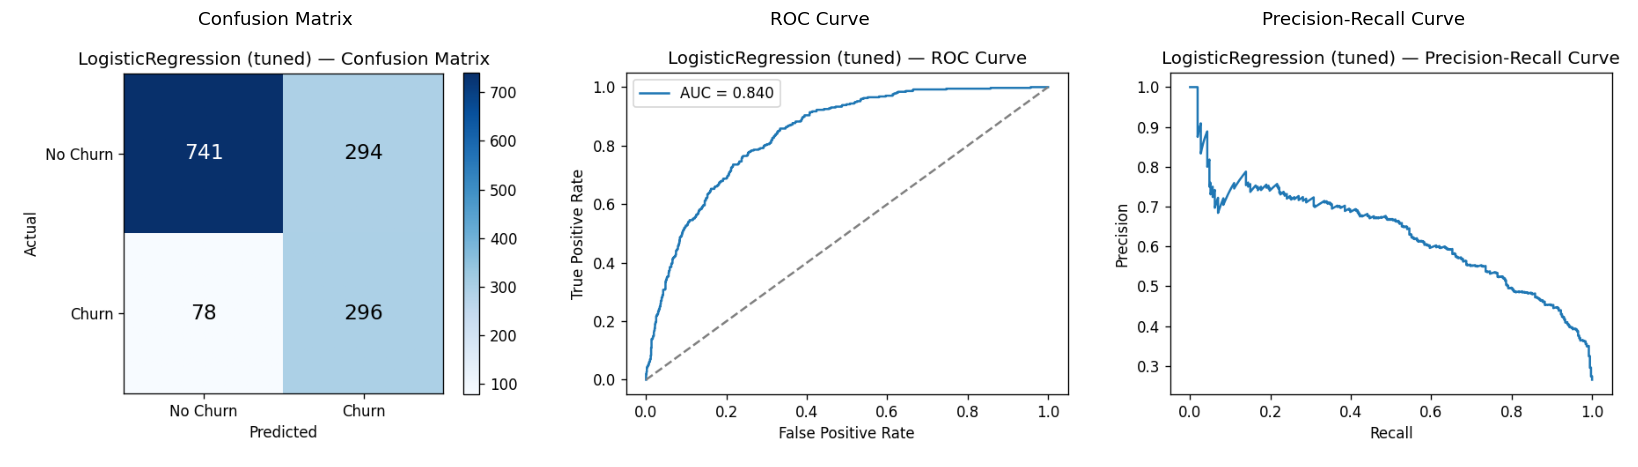

In [6]:
import matplotlib.pyplot as plt
import matplotlib.image as mpimg
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))
for ax, name, title in zip(
    axes,
    ['confusion_matrix.png', 'roc_curve.png', 'pr_curve.png'],
    ['Confusion Matrix', 'ROC Curve', 'Precision-Recall Curve'],
):
    img = mpimg.imread(f'../reports/figures/{name}')
    ax.imshow(img)
    ax.axis('off')
    ax.set_title(title)
plt.tight_layout()
plt.show()


## Top churn drivers (feature importance)

                        feature  importance
              ContractRiskScore    0.431651
                         tenure    0.409797
                 MonthlyCharges    0.297127
    InternetService_Fiber optic    0.234130
         TenureGroup_0-12 (New)    0.223912
            InternetService_DSL    0.223892
            PaperlessBilling_No    0.197368
              Contract_Two year    0.180565
               MultipleLines_No    0.165691
              IsElectronicCheck    0.152146
        Contract_Month-to-month    0.149429
TenureGroup_25-48 (Established)    0.147977
               PhoneService_Yes    0.139241
                 Dependents_Yes    0.132965
              HasOnlineSecurity    0.125299


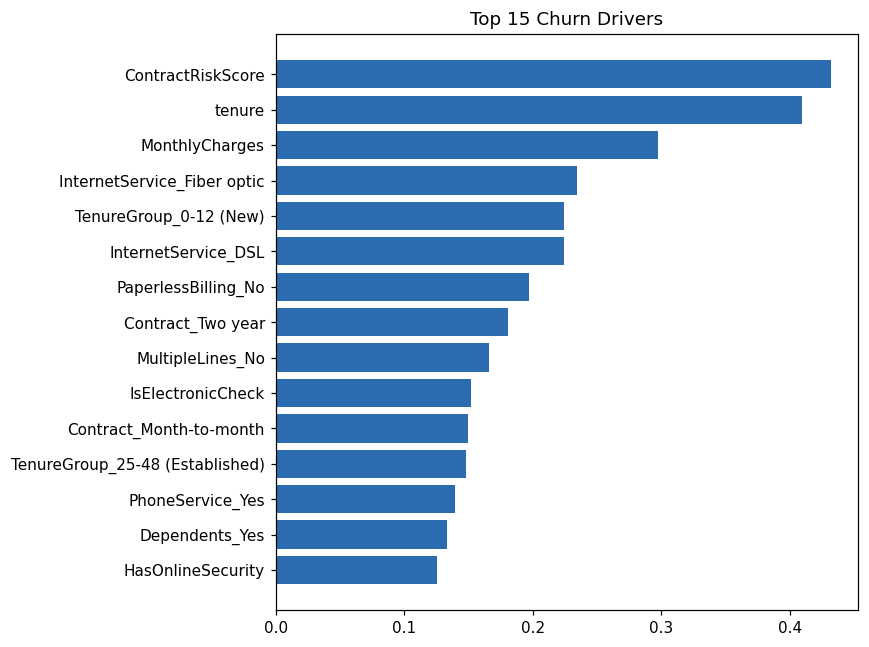

In [7]:
fi = pd.read_csv('../reports/feature_importance.csv').head(15)
fi['feature'] = fi['feature'].str.replace('num__','').str.replace('cat__','')
fig, ax = plt.subplots(figsize=(8,6))
ax.barh(fi['feature'][::-1], fi['importance'][::-1], color='#2b6cb0')
ax.set_title('Top 15 Churn Drivers')
plt.tight_layout()
plt.show()
print(fi.to_string(index=False))


**Important:** this is model feature importance (which features the
model relies on most to make predictions), not a causal claim. High
importance means the feature carries strong predictive signal within this
model — it does not prove that changing that feature would change a
customer's actual likelihood to churn.

## Correlation vs. model importance — a quick illustration

In [8]:
from data_preprocessing import load_raw_data, clean_data
from feature_engineering import engineer_features
raw = load_raw_data('../data/raw/WA_Fn-UseC_-Telco-Customer-Churn.csv')
df = engineer_features(clean_data(raw))

# Simple point-biserial-style correlation of a few numeric features with churn
num_cols = ['tenure','MonthlyCharges','TotalCharges','ServiceCount','ContractRiskScore']
corr = df[num_cols + ['ChurnFlag']].corr()['ChurnFlag'].drop('ChurnFlag').sort_values(key=abs, ascending=False)
print("Raw correlation with churn (not the same as model importance):")
print(corr.round(3))


Raw correlation with churn (not the same as model importance):
ContractRiskScore    0.397
tenure              -0.352
TotalCharges        -0.198
MonthlyCharges       0.193
ServiceCount        -0.088
Name: ChurnFlag, dtype: float64


Correlation measures a raw pairwise linear relationship between one
feature and churn in isolation. Model feature importance measures how
much the model actually relies on that feature **after accounting for all
other features together** — the two can (and do, e.g. for `TotalCharges`,
which is collinear with `tenure`) disagree. Neither one is a causal
estimate.

## Model saving

The complete pipeline — preprocessing (`ColumnTransformer`) **and** the
trained classifier — is saved as a single object via `joblib` to
`models/churn_model.pkl`. Loading that one file and calling
`.predict_proba()` on raw-shaped feature columns is guaranteed to apply
the exact same preprocessing used at training time, eliminating any
train/inference mismatch risk.

Next: `src/predict.py` turns this saved pipeline into customer-level churn
probabilities, risk segments, and business recommendations (see
`reports/model_report.md` and the Streamlit dashboard in `app/app.py`).